  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
FOODVISION - QWEN VISION
GPU: Tesla T4

Loading Qwen2.5-VL-3B-Instruct...


config.json:   0%|          | 0.00/1.37k [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/65.4k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/824 [00:00<?, ?it/s]

... (5 outputs left out)

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

Model loaded successfully.
Loading time: 139.18 seconds

Upload your food image:


Saving burger.jpg to burger.jpg
Uploaded: burger.jpg


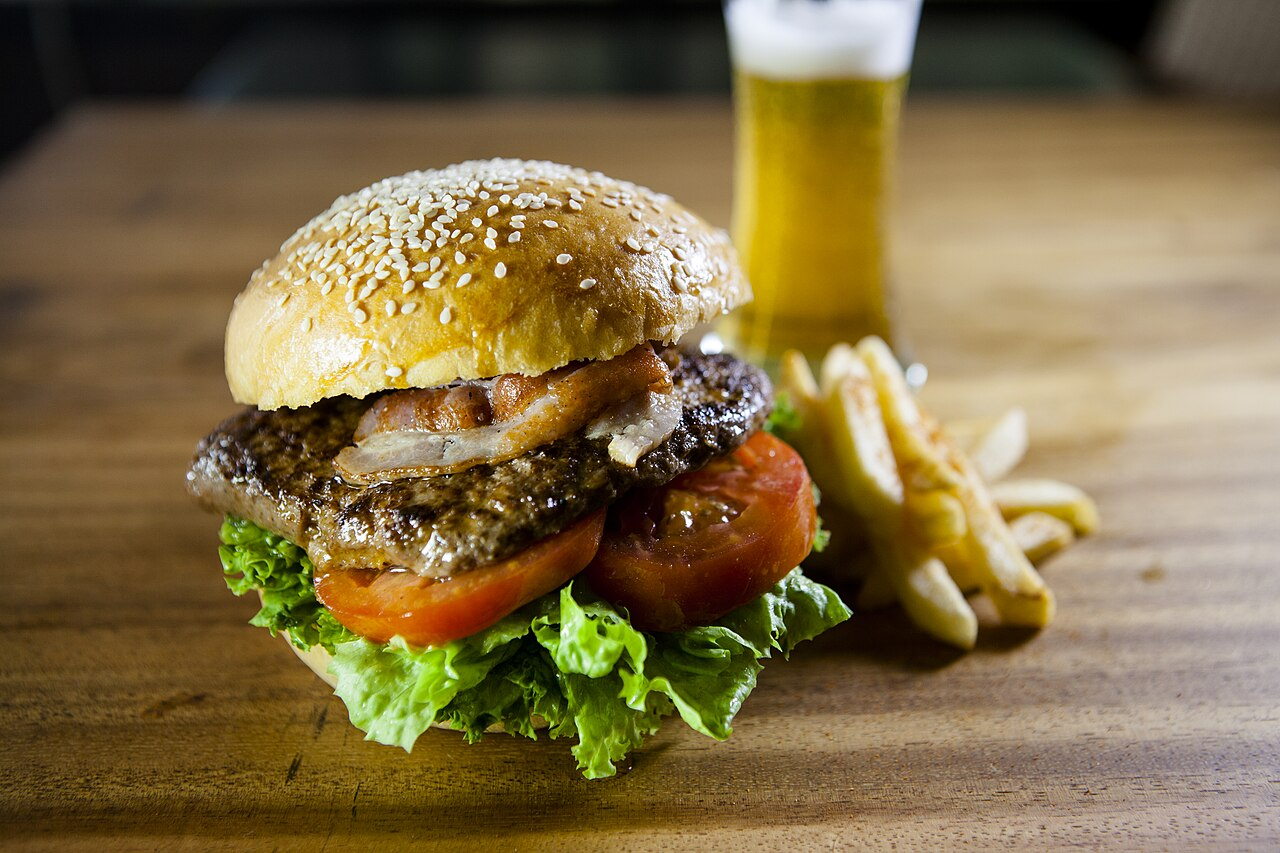

/usr/local/lib/python3.13/dist-packages/transformers/models/qwen2_vl/image_processing_qwen2_vl.py:129: FutureWarning: Passing `min_pixels` and `max_pixels` to a processor call is deprecated and will be removed in v5.23. Pass in `size={'longest_edge': xxx, 'shortest_edge': xxx} to override the target size.`
  warnings.warn(



Analyzing image with Qwen Vision...

FOODVISION ANALYSIS


- **FOOD IDENTIFICATION**
  - Main Food: Hamburger
  - Other Visible Food Items: French fries

- **INGREDIENT ANALYSIS**
  - **Bun**: Sesame seed bun
  - **Meat**: Beef patty with visible fat
  - **Bacon**: Slices of bacon
  - **Lettuce**: Fresh lettuce leaves
  - **Tomato**: Sliced tomato
  - **Fries**: French fries

- **FOOD CLASSIFICATION**
  - The meal is a classic hamburger with additional bacon slices and fresh vegetables.

- **MEAL DESCRIPTION**
  - The meal consists of a beef patty sandwiched between a sesame seed bun, topped with bacon slices, fresh lettuce, and sliced tomatoes. It is served alongside a side of French fries on a wooden surface.

- **VISUAL CHARACTERISTICS**
  - **Colors**: The burger has a golden-brown bun, dark brown meat, pinkish bacon, green lettuce, and red tomato. The fries are golden-yellow.
  - **Textures**: The bun appears soft and slightly crispy, the meat is juicy and tender, the bacon is crisp, the lettuce is crisp and fresh, the tomato is juicy, and the fries are crispy.
  - **Arrangement**: The burger is placed in the center of the frame, with the fries to its right. The background is blurred, focusing attention on the meal.

- **LIMITATIONS**
  - The image does not provide detailed nutritional information about the ingredients.
  - The exact type of beer in the glass cannot be determined from the image alone.


PERFORMANCE
Model: Qwen/Qwen2.5-VL-3B-Instruct
Device: Tesla T4
Model loading: 139.18 seconds
Inference time: 17.56 seconds
Experiment completed.


In [1]:

# ============================================================
# FOODVISION: QWEN2.5-VL-3B-INSTRUCT
# Multimodal Food Image Understanding
# Google Colab - Single Cell
# ============================================================

# 1. INSTALL DEPENDENCIES

!pip -q install -U git+https://github.com/huggingface/transformers
!pip -q install -U accelerate qwen-vl-utils

import torch
import time

from PIL import Image
from google.colab import files
from IPython.display import display, Markdown

from transformers import (
    Qwen2_5_VLForConditionalGeneration,
    AutoProcessor
)

from qwen_vl_utils import process_vision_info

# 2. CONFIGURATION

MODEL_ID = "Qwen/Qwen2.5-VL-3B-Instruct"

print("FOODVISION - QWEN VISION")
print("========================")

if not torch.cuda.is_available():
    raise RuntimeError(
        "GPU not detected. Go to Runtime > Change runtime type > T4 GPU."
    )

print("GPU:", torch.cuda.get_device_name(0))

# 3. LOAD MODEL

print("\nLoading Qwen2.5-VL-3B-Instruct...")

load_start = time.perf_counter()

model = Qwen2_5_VLForConditionalGeneration.from_pretrained(
    MODEL_ID,
    torch_dtype=torch.float16,
    device_map="auto",
    attn_implementation="sdpa"
)

processor = AutoProcessor.from_pretrained(
    MODEL_ID,
    min_pixels=256 * 28 * 28,
    max_pixels=1280 * 28 * 28
)

load_time = time.perf_counter() - load_start

print("Model loaded successfully.")
print("Loading time:", round(load_time, 2), "seconds")

# 4. UPLOAD FOOD IMAGE

print("\nUpload your food image:")

uploaded = files.upload()

if not uploaded:
    raise ValueError("No image uploaded.")

filename = next(iter(uploaded))

image = Image.open(filename).convert("RGB")

print("Uploaded:", filename)
display(image)

# 5. DEFINE FOODVISION PROMPT

prompt = """
You are FoodVision, an AI food image understanding system.

Analyze the uploaded image and provide:

1. FOOD IDENTIFICATION
   Identify the main food and other visible food items.

2. INGREDIENT ANALYSIS
   Describe the visible ingredients and components.
   Distinguish observations from uncertain guesses.

3. FOOD CLASSIFICATION
   Identify the most likely food category.

4. MEAL DESCRIPTION
   Describe the meal, presentation, and surroundings.

5. VISUAL CHARACTERISTICS
   Describe colors, textures, cooking style,
   and food arrangement.

6. LIMITATIONS
   Explain anything that cannot be reliably
   identified from the image alone.

Use clear headings and concise bullet points.
Do not invent ingredients or nutritional information.
"""

# 6. PREPARE IMAGE AND PROMPT

messages = [
    {
        "role": "user",
        "content": [
            {
                "type": "image",
                "image": filename
            },
            {
                "type": "text",
                "text": prompt
            }
        ]
    }
]

text = processor.apply_chat_template(
    messages,
    tokenize=False,
    add_generation_prompt=True
)

image_inputs, video_inputs = process_vision_info(messages)

inputs = processor(
    text=[text],
    images=image_inputs,
    videos=video_inputs,
    padding=True,
    return_tensors="pt"
)

inputs = inputs.to("cuda")

# 7. RUN VISION MODEL

print("\nAnalyzing image with Qwen Vision...")

start_time = time.perf_counter()

with torch.inference_mode():
    generated_ids = model.generate(
        **inputs,
        max_new_tokens=350,
        do_sample=False
    )

inference_time = time.perf_counter() - start_time

# 8. DECODE RESULTS

generated_ids_trimmed = [
    output_ids[len(input_ids):]
    for input_ids, output_ids in zip(
        inputs.input_ids,
        generated_ids
    )
]

output_text = processor.batch_decode(
    generated_ids_trimmed,
    skip_special_tokens=True,
    clean_up_tokenization_spaces=False
)[0]

# 9. DISPLAY FOODVISION RESULTS

print("\nFOODVISION ANALYSIS")
print("===================")

display(Markdown(output_text))

# 10. PERFORMANCE SUMMARY

print("\nPERFORMANCE")
print("===========")
print("Model:", MODEL_ID)
print("Device:", torch.cuda.get_device_name(0))
print("Model loading:", round(load_time, 2), "seconds")
print("Inference time:", round(inference_time, 2), "seconds")
print("Experiment completed.")
